1. Select three datasets to perform your analysis on. For example, you can use the Adult, German, and COMPAS datasets.

In [ ]:
import io
import re
from contextlib import redirect_stdout

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow.compat.v1 as tf
from aif360.sklearn.datasets import fetch_adult, fetch_compas, fetch_german
from aif360.sklearn.inprocessing import AdversarialDebiasing
from aif360.sklearn.metrics import consistency_score, disparate_impact_ratio, statistical_parity_difference
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

tf.disable_eager_execution()


def encode_y(y):
    # encode labels into numbers instead of strings and save the encoder to be able to reverse the encoding
    label_encoder = LabelEncoder()
    y_encoded = pd.Series(label_encoder.fit_transform(y), index=y.index, name=y.name)
    return y_encoded, label_encoder


# Adult Census Income (Adult)
adult = fetch_adult(subset="all")  # adult comes pre-split, but we load unsplit version instead
adult_X, (adult_y, adult_encoder) = adult.X, encode_y(adult.y)

# German Credit Data (German)
german = fetch_german()
german_X, (german_y, german_encoder) = german.X, encode_y(german.y)

# COMPAS Recidivism Racial Bias (COMPAS)
compas = fetch_compas(subset="all")
compas_X, (compas_y, compas_encoder) = compas.X, encode_y(compas.y)


2. Compute the demographic parity difference (DP_Diff), the disparate impact ratio (DIR), and the consistency from the original labels of the dataset before mitigation and training any classifiers.

In [ ]:
# one hot encode all columns that are categorical to be able to use them for metric computation and model training
def bulk_encode(X):
    categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns
    return pd.get_dummies(X, columns=categorical_cols, dtype=float)


adult_X = bulk_encode(adult_X)
german_X = bulk_encode(german_X)
compas_X = bulk_encode(compas_X)


def print_fairness(X, y, prot_attr, priv_group, positive_label=1, dataset=""):
    y = pd.Series(y, index=X.index, name="prediction")
    dp_diff = statistical_parity_difference(y, prot_attr=prot_attr, priv_group=priv_group, pos_label=positive_label)
    dir_value = disparate_impact_ratio(
        y, prot_attr=prot_attr, priv_group=priv_group, pos_label=positive_label, zero_division=0
    )
    consistency = consistency_score(X, y, n_neighbors=5)
    print(f"[{dataset}]: DP_Diff {dp_diff:.3f}, DIR {dir_value:.3f}, Consistency {consistency:.3f}")


print_fairness(adult_X, adult_y, prot_attr="sex", priv_group="Male", dataset="ADULT")
print_fairness(german_X, german_y, prot_attr="sex", priv_group="male", dataset="GERMAN")
print_fairness(compas_X, compas_y, prot_attr="race", priv_group="Caucasian", dataset="COMPAS")

[ADULT]: DP_Diff -0.199, DIR 0.363, Consistency 0.848
[GERMAN]: DP_Diff -0.075, DIR 0.897, Consistency 0.681
[COMPAS]: DP_Diff -0.097, DIR 0.840, Consistency 0.676


3. Perform a train/test split with stratification.

In [ ]:
# stratified train test splitting and scaling based on train, applied to holdout
def scale_split(X_train, X_holdout):
    scaler = StandardScaler().fit(X_train)

    def transform(X):
        return pd.DataFrame(scaler.transform(X), index=X.index, columns=X.columns)

    return transform(X_train), transform(X_holdout)


adult_X_train, adult_X_holdout, adult_y_train, adult_y_holdout = train_test_split(
    adult_X, adult_y, test_size=0.2, random_state=0, stratify=adult_y
)
german_X_train, german_X_holdout, german_y_train, german_y_holdout = train_test_split(
    german_X, german_y, test_size=0.2, random_state=0, stratify=german_y
)
compas_X_train, compas_X_holdout, compas_y_train, compas_y_holdout = train_test_split(
    compas_X, compas_y, test_size=0.2, random_state=0, stratify=compas_y
)

adult_X_train, adult_X_holdout = scale_split(adult_X_train, adult_X_holdout)
german_X_train, german_X_holdout = scale_split(german_X_train, german_X_holdout)
compas_X_train, compas_X_holdout = scale_split(compas_X_train, compas_X_holdout)


4. Follow the appropriate procedure for the selected method: pre-processing methods modify training data, in-processing methods are used during model training, and post-processing methods modify predictions after training.

In [ ]:
# regex to extract numbers from what the library prints
LOG_PATTERN = re.compile(r"epoch\s+(\d+).*?classifier loss: ([\d.]+).*?adversarial loss: ([\d.]+)")


def adversarial_debiasing(
    X_train,
    y_train,
    X_holdout,
    prot_attr,
    adversary_loss_weight=None,  # None is the paper's a = sqrt(t)
    batch_size=128,
    num_epochs=50,
    debias=True,
    verbose=True,
    random_state=0,
):
    model = AdversarialDebiasing(
        prot_attr=prot_attr,
        adversary_loss_weight=adversary_loss_weight,
        batch_size=batch_size,
        num_epochs=num_epochs,
        debias=debias,
        verbose=verbose,
        random_state=random_state,
    )

    buffer = io.StringIO()  # fit the model in a buffer so we can capture the output
    with redirect_stdout(buffer):
        model.fit(X_train, y_train)
    model.history_ = pd.DataFrame(
        LOG_PATTERN.findall(buffer.getvalue()),
        columns=["epoch", "classifier_loss", "adversary_loss"],
    ).astype(float)

    return model, model.predict(X_holdout)


# run adversarial debiasing for all loaded datasets, save the model and the predictions
# both a debiased and a biased model are trained so they can be compared afterwards
adult_args = [adult_X_train, adult_y_train, adult_X_holdout, "sex"]
adult_kwargs = {}
adult_model_biased, adult_y_hat_biased = adversarial_debiasing(*adult_args, **adult_kwargs, debias=False, verbose=False)
adult_model, adult_y_hat = adversarial_debiasing(*adult_args, **adult_kwargs)

# smaller batch_size used as the german dataset is small
german_args = [german_X_train, german_y_train, german_X_holdout, "sex"]
german_kwargs = {"batch_size": 16}
german_model_biased, german_y_hat_biased = adversarial_debiasing(
    *german_args, **german_kwargs, debias=False, verbose=False
)
german_model, german_y_hat = adversarial_debiasing(*german_args, **german_kwargs)

compas_args = [compas_X_train, compas_y_train, compas_X_holdout, "race"]
compas_kwargs = {"batch_size": 16}
compas_model_biased, compas_y_hat_biased = adversarial_debiasing(
    *compas_args, **compas_kwargs, debias=False, verbose=False
)
compas_model, compas_y_hat = adversarial_debiasing(*compas_args, **compas_kwargs)

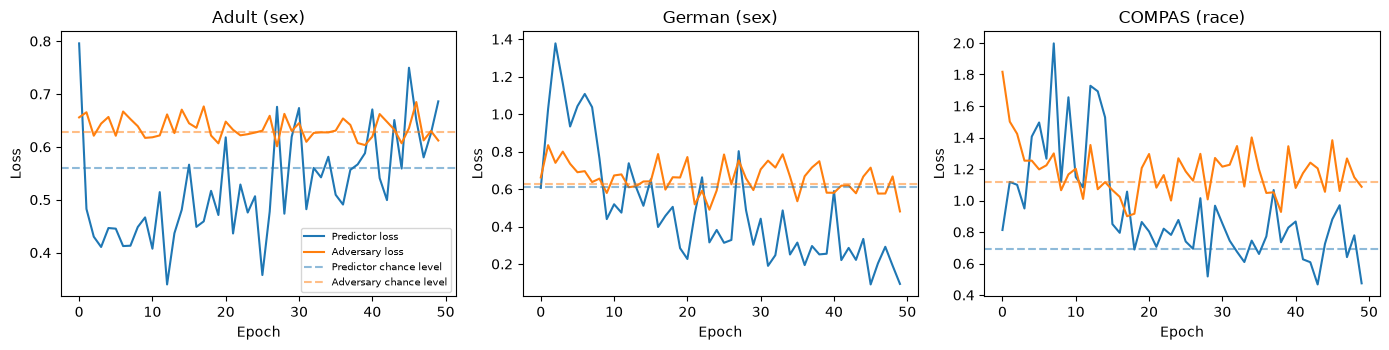

In [ ]:
# plot the training curves of the two adversaries

# the entropy line signifies guessing randomly with the right proportions
# if the model is below the line, it has learned something
def entropy(s):
    p = pd.Series(s).value_counts(normalize=True)
    return float(-(p * np.log(p)).sum())


# plots the datapoints extracted from the model's training run
def plot_training(models, titles, X_trains, y_trains, prot_attrs):
    _, axes = plt.subplots(1, len(models), figsize=(14, 3.6))
    for ax, m, title, X, y, prot in zip(axes, models, titles, X_trains, y_trains, prot_attrs):
        h = m.history_.groupby("epoch")[["classifier_loss", "adversary_loss"]].mean()
        ax.plot(h.index, h["classifier_loss"], label="Predictor loss")
        ax.plot(h.index, h["adversary_loss"], label="Adversary loss")
        ax.axhline(entropy(y), ls="--", c="C0", alpha=0.5, label="Predictor chance level")
        ax.axhline(entropy(X.index.get_level_values(prot)), ls="--", c="C1", alpha=0.5, label="Adversary chance level")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
    axes[0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()


plot_training(
    [adult_model, german_model, compas_model],
    ["Adult (sex)", "German (sex)", "COMPAS (race)"],
    [adult_X_train, german_X_train, compas_X_train],
    [adult_y_train, german_y_train, compas_y_train],
    ["sex", "sex", "race"],
)

5. On the held-out test data, report the demographic parity difference (DP_Diff), the disparate impact ratio (DIR), the consistency, and at least one predictive-performance measure from the final predictions after applying the complete mitigation pipeline.

In [ ]:
def print_predictive_performance(y_true, y_hat, dataset=""):
    print(
        f"""[{dataset}]: Accuracy: {accuracy_score(y_true, y_hat):.2f}, """
        f"""Precision: {precision_score(y_true, y_hat, zero_division=0):.2f}, """
        f"""Recall: {recall_score(y_true, y_hat, zero_division=0):.2f}, """
        f"""F1-score: {f1_score(y_true, y_hat, zero_division=0):.2f}"""
    )


print_fairness(adult_X_holdout, adult_y_hat, prot_attr="sex", priv_group="Male", dataset="ADULT debiased fairness")
print_predictive_performance(adult_y_holdout, adult_y_hat, dataset="ADULT debiased performance")
print()  # newline
print_fairness(german_X_holdout, german_y_hat, prot_attr="sex", priv_group="male", dataset="GERMAN debiased fairness")
print_predictive_performance(german_y_holdout, german_y_hat, dataset="GERMAN debiased performance")
print()
print_fairness(
    compas_X_holdout, compas_y_hat, prot_attr="race", priv_group="Caucasian", dataset="COMPAS debiased fairness"
)
print_predictive_performance(compas_y_holdout, compas_y_hat, dataset="COMPAS debiased performance")

[ADULT debiased fairness]: DP_Diff 0.078, DIR 19.721, Consistency 0.992
[ADULT debiased performance]: Accuracy: 0.76, Precision: 0.70, Recall: 0.08, F1-score: 0.15

[GERMAN debiased fairness]: DP_Diff 0.005, DIR 1.007, Consistency 0.744
[GERMAN debiased performance]: Accuracy: 0.74, Precision: 0.81, Recall: 0.81, F1-score: 0.81

[COMPAS debiased fairness]: DP_Diff 0.091, DIR 2.724, Consistency 0.911
[COMPAS debiased performance]: Accuracy: 0.51, Precision: 0.74, Recall: 0.15, F1-score: 0.25


6. Compare the values of the fairness measures before and after the bias mitigation.

In [ ]:
print_fairness(
    adult_X_holdout, adult_y_hat_biased, prot_attr="sex", priv_group="Male", dataset="ADULT baseline fairness"
)
print_fairness(adult_X_holdout, adult_y_hat, prot_attr="sex", priv_group="Male", dataset="ADULT debiased fairness")
print_predictive_performance(adult_y_holdout, adult_y_hat_biased, dataset="ADULT baseline performance")
print_predictive_performance(adult_y_holdout, adult_y_hat, dataset="ADULT debiased performance")
print()
print_fairness(
    german_X_holdout, german_y_hat_biased, prot_attr="sex", priv_group="male", dataset="GERMAN baseline fairness"
)
print_fairness(german_X_holdout, german_y_hat, prot_attr="sex", priv_group="male", dataset="GERMAN debiased fairness")
print_predictive_performance(german_y_holdout, german_y_hat_biased, dataset="GERMAN baseline performance")
print_predictive_performance(german_y_holdout, german_y_hat, dataset="GERMAN debiased performance")
print()
print_fairness(
    compas_X_holdout, compas_y_hat_biased, prot_attr="race", priv_group="Caucasian", dataset="COMPAS baseline fairness"
)
print_fairness(
    compas_X_holdout, compas_y_hat, prot_attr="race", priv_group="Caucasian", dataset="COMPAS debiased fairness"
)
print_predictive_performance(compas_y_holdout, compas_y_hat_biased, dataset="COMPAS baseline performance")
print_predictive_performance(compas_y_holdout, compas_y_hat, dataset="COMPAS debiased performance")

[ADULT baseline fairness]: DP_Diff -0.179, DIR 0.349, Consistency 0.928
[ADULT debiased fairness]: DP_Diff 0.078, DIR 19.721, Consistency 0.992
[ADULT baseline performance]: Accuracy: 0.85, Precision: 0.72, Recall: 0.63, F1-score: 0.67
[ADULT debiased performance]: Accuracy: 0.76, Precision: 0.70, Recall: 0.08, F1-score: 0.15

[GERMAN baseline fairness]: DP_Diff -0.209, DIR 0.739, Consistency 0.785
[GERMAN debiased fairness]: DP_Diff 0.005, DIR 1.007, Consistency 0.744
[GERMAN baseline performance]: Accuracy: 0.74, Precision: 0.80, Recall: 0.85, F1-score: 0.82
[GERMAN debiased performance]: Accuracy: 0.74, Precision: 0.81, Recall: 0.81, F1-score: 0.81

[COMPAS baseline fairness]: DP_Diff -0.129, DIR 0.811, Consistency 0.765
[COMPAS debiased fairness]: DP_Diff 0.091, DIR 2.724, Consistency 0.911
[COMPAS baseline performance]: Accuracy: 0.67, Precision: 0.68, Recall: 0.75, F1-score: 0.71
[COMPAS debiased performance]: Accuracy: 0.51, Precision: 0.74, Recall: 0.15, F1-score: 0.25
